# ITRI625: Phishing Email Detection
## 1. Project Overview
Develop a reproducible cybersecurity text classifier that labels a message **Phishing** or **Legitimate**. This notebook contains the full model-development workflow, including executable training code and embedded results. The API and desktop application reuse its saved vectorizer and selected model.

Run **Restart Kernel → Run All** with the **ITRI625 Phishing** kernel. Paths are relative to the repository; no machine-specific path is required. A rerun repeats the fixed experiment, including the final evaluation; do not tune choices after viewing test results.

## 2. Cybersecurity Scenario
Phishing messages impersonate trusted senders to persuade people to disclose credentials, transfer money, or open harmful links. A text classifier can help prioritise messages for human review. A false negative is a phishing-labelled message classified as legitimate; it can leave a user exposed to account theft or fraud.

**Dataset limitation:** the supplied corpus includes spam as well as phishing. Therefore the output is a prediction of the supplied label, not proof of malicious intent or safety. Text-only analysis cannot validate senders, attachments, link destinations, or live threats.

## 3. Dataset Description
The assignment links the [Naser Abdullah Alam phishing email dataset](https://www.kaggle.com/datasets/naserabdullahalam/phishing-email-dataset). The supplied archive contains seven CSVs. We use only `phishing_email.csv`, the combined two-column file; concatenating it with constituent files could duplicate examples.

- **TEXT FEATURE:** `text_combined`, the supplied processed message text.
- **TARGET:** `label`, observed integer classes 0 and 1.
- **Mapping:** 0 = Legitimate; 1 = Phishing. Inspection of the supplied positive-only `Nazario.csv` and `Nigerian_Fraud.csv` found label 1, while normal Enron correspondence carries label 0. The source describes spam/phishing and legitimate classes. There is no separate label dictionary in the archive.
- The combined CSV lacks timestamps, source IDs, and campaign IDs. Random splitting cannot establish performance on future campaigns.

The original archive and extracted raw CSV remain unchanged. SHA-256 records verify the raw input. Upstream preprocessing is not supplied; our explicit vectorizer is reused unchanged at inference, but raw real-world emails may have a different distribution.

## 4. Imports and Configuration

In [1]:
from pathlib import Path
import copy
import hashlib
import json
import platform
import time
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display, Markdown
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, average_precision_score)
from threadpoolctl import threadpool_limits

%matplotlib inline
ROOT = Path.cwd() if (Path.cwd() / 'data/raw/phishing_email.csv').exists() else Path.cwd().parent
DATA_PATH = ROOT / 'data/raw/phishing_email.csv'
assert DATA_PATH.exists(), 'Extract phishing_email.csv into data/raw first.'
for folder in ['models', 'figures', 'reports']:
    (ROOT / folder).mkdir(exist_ok=True)
SEED = 42
THRESHOLD = 0.5  # Fixed before training; not tuned on test data.
MAX_EPOCHS = 30
PATIENCE = 3
LABELS = {0: 'Legitimate', 1: 'Phishing'}
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.max_columns', 20)
print({'python': platform.python_version(), 'sklearn': sklearn.__version__,
       'pandas': pd.__version__, 'seed': SEED})

def show_figure(name):
    plt.tight_layout()
    plt.savefig(ROOT / 'figures' / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

{'python': '3.13.3', 'sklearn': '1.9.0', 'pandas': '3.0.5', 'seed': 42}


## 5. Data Loading

In [2]:
raw_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
integrity = json.loads((ROOT / 'reports/data_integrity.json').read_text())
assert raw_sha256 == integrity['csv_sha256'], 'Raw dataset differs from inspected archive.'
df = pd.read_csv(DATA_PATH)
assert list(df.columns) == ['text_combined', 'label'], 'Unexpected dataset schema; inspect before proceeding.'
print('File:', DATA_PATH.relative_to(ROOT), 'Shape:', df.shape)
display(df.head())
df.info()
display(df.describe(include='all'))
print('Class names:', LABELS)
print('Observed labels:', df['label'].unique())
display(df['label'].value_counts(dropna=False).rename('count').to_frame())
display(df.isna().sum().rename('missing_values').to_frame())
print('Duplicate rows:', df.duplicated().sum())
print('Blank/whitespace-only texts:', df.text_combined.fillna('').str.strip().eq('').sum())

File: data/raw/phishing_email.csv Shape: (82486, 2)


,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 525 xls hplno 525 xls,0
1,nom actual vols 24 th forwarded sabrae zajac hou ect 05 30 2001 12 07 pm enron capital trade resources corp eileen ponton 05 29 2001 08 37 davilal txu com c...,0
2,enron actuals march 30 april 1 201 estimated actuals march 30 2001 flow march 31 2001 flow april 1 2001 teco tap 35 000 receive actuals duke forward,0
3,hpl nom may 30 2001 see attached file hplno 530 xls hplno 530 xls,0
4,hpl nom june 1 2001 see attached file hplno 601 xls hplno 601 xls,0


<class 'pandas.DataFrame'>
RangeIndex: 82486 entries, 0 to 82485
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   text_combined  82486 non-null  str  
 1   label          82486 non-null  int64
dtypes: int64(1), str(1)
memory usage: 1.3 MB


,text_combined,label
count,82486,82486.000000
unique,82078,NaN
top,charity sees need cost dear friend read want feel sorry believe everyone die someday name mr reza abdulla merchant safat kuwait married two children wife tw...,NaN
freq,3,NaN
mean,NaN,0.519979
std,NaN,0.499604
min,NaN,0.000000
25%,NaN,0.000000
50%,NaN,1.000000
75%,NaN,1.000000


Class names: {0: 'Legitimate', 1: 'Phishing'}
Observed labels: [0 1]


,count
label,
1,42891
0,39595


,missing_values
text_combined,0
label,0


Duplicate rows: 408
Blank/whitespace-only texts: 1


## 6. Exploratory Data Analysis
These descriptive plots show the raw dataset, including rows later removed during cleaning. They do not fit a vocabulary or determine model settings. Message lengths are measured in characters. The logarithmic length axis makes the long tail visible without silently deleting long messages.

,class,count,percentage
0,Legitimate,39595,48.002085
1,Phishing,42891,51.997915


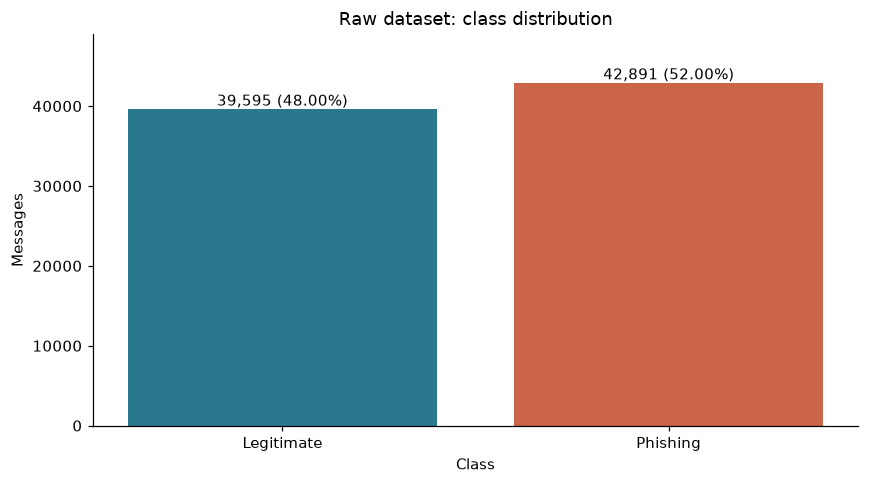

characters                                                         \
                count         mean           std   min    25%    50%     75%   
class                                                                          
Legitimate    39595.0  1536.096098   3695.897909  11.0  411.0  779.0  1493.0   
Phishing      42891.0  1060.413793  21192.696303   1.0  241.0  391.0  1058.0   

                       
                  max  
class                  
Legitimate   160318.0  
Phishing    4279526.0

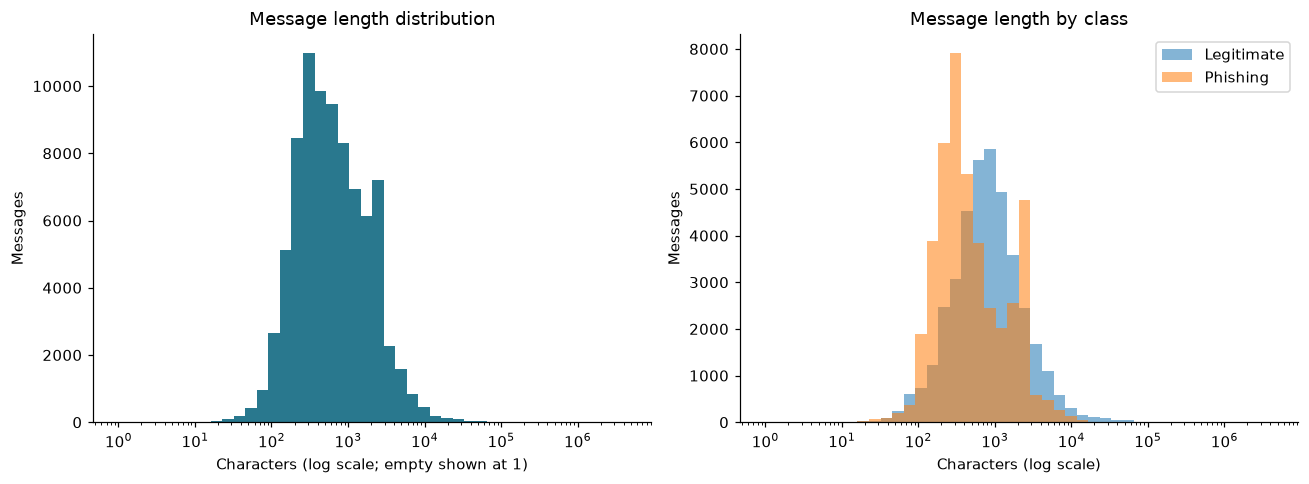

Maximum/minimum class-count ratio: 1.083
The classes are approximately balanced; no resampling is used.


In [3]:
class_counts = df['label'].value_counts().sort_index()
class_table = pd.DataFrame({'class': [LABELS[int(i)] for i in class_counts.index],
                            'count': class_counts.values,
                            'percentage': 100 * class_counts.values / len(df)})
display(class_table)
fig, ax = plt.subplots()
bars = ax.bar(class_table['class'], class_table['count'], color=['#29788e', '#cb6548'])
ax.bar_label(bars, labels=[f'{n:,} ({p:.2f}%)' for n,p in zip(class_table['count'],class_table['percentage'])])
ax.set(title='Raw dataset: class distribution', xlabel='Class', ylabel='Messages', ylim=(0, 49000))
show_figure('class_distribution')
lengths = df['text_combined'].fillna('').str.len()
display(pd.DataFrame({'class': df['label'].map(LABELS), 'characters': lengths}).groupby('class').describe())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bins = np.geomspace(1, max(2, lengths.max()), 45)
axes[0].hist(lengths.clip(lower=1), bins=bins, color='#29788e')
axes[0].set(xscale='log', xlabel='Characters (log scale; empty shown at 1)', ylabel='Messages', title='Message length distribution')
for label in [0, 1]:
    axes[1].hist(lengths[df.label == label].clip(lower=1), bins=bins, alpha=0.55, label=LABELS[label])
axes[1].set(xscale='log', xlabel='Characters (log scale)', ylabel='Messages', title='Message length by class')
axes[1].legend()
show_figure('message_lengths')
print('Maximum/minimum class-count ratio:', round(class_counts.max()/class_counts.min(), 3))
print('The classes are approximately balanced; no resampling is used.')

## 7. Data Cleaning
Every removal is counted below. We remove missing/blank text, invalid/missing labels, and texts with no usable word tokens. We then detect conflicting labels for token-equivalent texts and exclude all rows in such groups rather than choosing a label arbitrarily. Finally we keep the first occurrence of each token-equivalent text.

The deduplication key uses the same unfitted analyser as TF-IDF: lowercase, Unicode accent stripping, word tokens of at least two characters. It learns nothing from the corpus. This removes punctuation/case variants that would otherwise appear identical to the model across sets. We do not relabel suspicious examples, drop long messages, or concatenate the source datasets. Near-duplicate campaigns with different wording can remain.

In [4]:
audit = []
clean = df.copy()
clean['source_row'] = clean.index

def remove_rows(reason, mask):
    global clean
    before = len(clean)
    clean = clean.loc[~mask].copy()
    audit.append({'decision': reason, 'rows_before': before,
                  'rows_removed': before - len(clean), 'rows_after': len(clean)})

remove_rows('Missing or blank text', clean.text_combined.isna() | clean.text_combined.fillna('').str.strip().eq(''))
remove_rows('Missing or unexpected target', ~clean.label.isin([0, 1]))
# Stateless tokenisation for duplicate detection; no vocabulary or IDF is fitted here.
analyser = TfidfVectorizer(strip_accents='unicode', lowercase=True).build_analyzer()
clean['text_key'] = clean.text_combined.map(lambda text: ' '.join(analyser(text)))
remove_rows('No usable tokens', clean.text_key.eq(''))
label_counts = clean.groupby('text_key')['label'].nunique()
conflicts = set(label_counts[label_counts > 1].index)
print('Conflicting token-equivalent text groups:', len(conflicts))
remove_rows('Conflicting labels for equivalent text', clean.text_key.isin(conflicts))
remove_rows('Repeated token-equivalent text', clean.text_key.duplicated(keep='first'))
clean['label'] = clean.label.astype(int)
clean = clean.reset_index(drop=True)
cleaning_table = pd.DataFrame(audit)
display(cleaning_table)
print(f'Rows before: {len(df):,}; removed: {len(df)-len(clean):,}; after: {len(clean):,}')
display(clean.label.map(LABELS).value_counts().rename('clean_count').to_frame())
cleaning_table.to_csv(ROOT / 'reports/cleaning_audit.csv', index=False)
assert clean.text_key.is_unique and set(clean.label) == {0, 1}

Conflicting token-equivalent text groups: 0


,decision,rows_before,rows_removed,rows_after
0,Missing or blank text,82486,1,82485
1,Missing or unexpected target,82485,0,82485
2,No usable tokens,82485,1,82484
3,Conflicting labels for equivalent text,82484,0,82484
4,Repeated token-equivalent text,82484,433,82051


Rows before: 82,486; removed: 435; after: 82,051


,clean_count
label,
Phishing,42838
Legitimate,39213


## 8. Text Preprocessing
TF-IDF gives a term more weight when it is frequent within a message but less common across training messages. We use word unigrams and bigrams, at most 10,000 features, and a minimum document frequency of 2. The vocabulary cap keeps CPU memory and training time manageable. Lowercasing and accent stripping are part of the fitted vectorizer's configuration. We retain stop words rather than introducing another language-specific preprocessing dependency.

The vectorizer is **fitted only after splitting, and only on training text**. Its saved instance is later placed in a Pipeline with the selected model. No separate application cleaning routine changes the features.

## 9. Train / Validation / Test Split

In [5]:
train, held_out = train_test_split(clean, test_size=0.30, stratify=clean.label, random_state=SEED)
validation, test = train_test_split(held_out, test_size=0.50, stratify=held_out.label, random_state=SEED)
parts = {'Training': train, 'Validation': validation, 'Test': test}
split_table = pd.DataFrame([
    {'split': name, 'samples': len(part), 'Legitimate': int((part.label == 0).sum()),
     'Phishing': int((part.label == 1).sum()), 'phishing_percent': float(100 * part.label.mean())}
    for name, part in parts.items()])
display(split_table)
for name, part in parts.items():
    print(f'{name} samples: {len(part):,}')
assert set(train.text_key).isdisjoint(validation.text_key)
assert set(train.text_key).isdisjoint(test.text_key)
assert set(validation.text_key).isdisjoint(test.text_key)
assert len(train) + len(validation) + len(test) == len(clean)
manifest = pd.concat([part[['source_row', 'label']].assign(split=name) for name,part in parts.items()])
manifest.to_csv(ROOT / 'reports/split_manifest.csv', index=False)
vectorizer = TfidfVectorizer(strip_accents='unicode', lowercase=True, ngram_range=(1, 2),
                             min_df=2, max_features=10000, sublinear_tf=True, dtype=np.float32)
X_train = vectorizer.fit_transform(train.text_combined)
X_val = vectorizer.transform(validation.text_combined)
y_train = train.label.to_numpy()
y_val = validation.label.to_numpy()
print('Training matrix:', X_train.shape, 'Validation matrix:', X_val.shape)
print('Test text is not transformed or predicted until final evaluation.')

,split,samples,Legitimate,Phishing,phishing_percent
0,Training,57435,27449,29986,52.208584
1,Validation,12308,5882,6426,52.209945
2,Test,12308,5882,6426,52.209945


Training samples: 57,435
Validation samples: 12,308
Test samples: 12,308


Training matrix: (57435, 10000) Validation matrix: (12308, 10000)
Test text is not transformed or predicted until final evaluation.


## 10. Baseline Model
Logistic Regression estimates the probability of the positive (Phishing) class from TF-IDF features. The decision threshold is fixed at 0.5. We evaluate this baseline on validation data. Precision measures how many alerts have positive labels; recall measures how many positive-labelled messages are found. F1 balances those two. ROC AUC evaluates ranking across thresholds; log loss also penalises confident mistakes.

,accuracy,precision,recall,f1,auc_roc,loss
Logistic Regression validation,0.986269,0.983764,0.99004,0.986892,0.998663,0.068009


Solver iterations: [31]
              precision    recall  f1-score   support

  Legitimate     0.9890    0.9821    0.9856      5882
    Phishing     0.9838    0.9900    0.9869      6426

    accuracy                         0.9863     12308
   macro avg     0.9864    0.9861    0.9862     12308
weighted avg     0.9863    0.9863    0.9863     12308



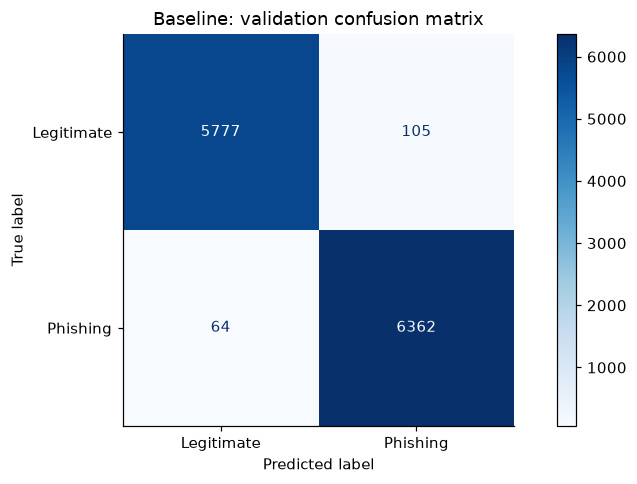

In [6]:
def metric_scores(y, probabilities):
    predictions = (probabilities >= THRESHOLD).astype(int)
    return {'accuracy': float(accuracy_score(y, predictions)),
            'precision': float(precision_score(y, predictions, zero_division=0)),
            'recall': float(recall_score(y, predictions, zero_division=0)),
            'f1': float(f1_score(y, predictions, zero_division=0)),
            'auc_roc': float(roc_auc_score(y, probabilities)),
            'loss': float(log_loss(y, probabilities, labels=[0, 1]))}

baseline = LogisticRegression(C=1.0, max_iter=1000, solver='lbfgs', random_state=SEED)
with threadpool_limits(limits=2):
    baseline.fit(X_train, y_train)
assert baseline.n_iter_.max() < baseline.max_iter, 'Baseline did not converge.'
baseline_val_prob = baseline.predict_proba(X_val)[:, 1]
baseline_metrics = metric_scores(y_val, baseline_val_prob)
display(pd.DataFrame([baseline_metrics], index=['Logistic Regression validation']))
print('Solver iterations:', baseline.n_iter_)
print(classification_report(y_val, baseline_val_prob >= THRESHOLD, target_names=['Legitimate','Phishing'], digits=4))
ConfusionMatrixDisplay.from_predictions(y_val, baseline_val_prob >= THRESHOLD, display_labels=['Legitimate','Phishing'], cmap='Blues')
plt.title('Baseline: validation confusion matrix')
show_figure('baseline_validation_confusion')

## 11. Main Model
Our neural network is a small multilayer perceptron (MLP):

**10,000 TF-IDF inputs → Dense(32, ReLU) → Dense(1, sigmoid).**

ReLU introduces nonlinear feature interactions; sigmoid produces a binary-class probability. Adam updates weights using minibatches of 256. L2 regularisation (`alpha=0.0001`) and validation-based early stopping limit overfitting. A compact TF-IDF network is practical on this CPU and keeps the baseline and neural model on the same input representation. It does not model long-range word order like an LSTM, and it does not use embedding or dropout layers.

We use scikit-learn's neural-network implementation, avoiding a second framework. [`partial_fit`](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) performs one iteration over the data. The explicit loop below monitors our separate validation set, rather than the library's internal accuracy-based stopping. We save and restore the best validation-loss model.

## 12. Training and Early Stopping
Requested epochs: 30. `monitor = val_loss`, `patience = 3`, `restore_best_weights = True`. After each epoch, we compute all six metrics on the full training and validation sets. Loss in the log is predictive binary cross-entropy measured at the epoch's end, excluding the regularisation term; the optimiser's internal loss is also recorded separately.

Three consecutive epochs without a lower validation loss stop training. The best checkpoint is restored even if the epoch cap is reached. Stopping limits continued fitting to training-specific details; it does not guarantee absence of overfitting.

In [7]:
neural = MLPClassifier(hidden_layer_sizes=(32,), activation='relu', solver='adam',
                       alpha=0.0001, batch_size=256, learning_rate_init=0.001,
                       max_iter=1, early_stopping=False, shuffle=True, random_state=SEED)
history_rows = []
best_loss = float('inf')
best_epoch = 0
best_neural = None
wait = 0
started = time.perf_counter()
with threadpool_limits(limits=2):
    for epoch in range(1, MAX_EPOCHS + 1):
        neural.partial_fit(X_train, y_train, classes=np.array([0, 1]))
        train_metrics = metric_scores(y_train, neural.predict_proba(X_train)[:, 1])
        val_metrics = metric_scores(y_val, neural.predict_proba(X_val)[:, 1])
        row = {'epoch': epoch, 'optimizer_loss': float(neural.loss_)}
        row.update({f'train_{k}': v for k,v in train_metrics.items()})
        row.update({f'val_{k}': v for k,v in val_metrics.items()})
        history_rows.append(row)
        pd.DataFrame(history_rows).to_csv(ROOT / 'reports/training_history.csv', index=False)
        print(f'Epoch {epoch:02d}: train loss={train_metrics["loss"]:.5f}, '
              f'val loss={val_metrics["loss"]:.5f}, val F1={val_metrics["f1"]:.5f}', flush=True)
        if val_metrics['loss'] < best_loss:
            best_loss = val_metrics['loss']
            best_epoch = epoch
            best_neural = copy.deepcopy(neural)
            wait = 0
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f'Early stopping triggered: {PATIENCE} epochs without improvement.')
                break
neural = best_neural  # Restore the full best checkpoint, including its weights.
history = pd.DataFrame(history_rows)
training_seconds = time.perf_counter() - started
neural_val_prob = neural.predict_proba(X_val)[:, 1]
neural_metrics = metric_scores(y_val, neural_val_prob)
assert np.isclose(neural_metrics['loss'], best_loss)
print({'requested_epochs': MAX_EPOCHS, 'trained_epochs': len(history), 'best_epoch': best_epoch,
       'best_validation_loss': best_loss, 'early_stopping_triggered': wait >= PATIENCE,
       'training_seconds': round(training_seconds, 2)})

Epoch 01: train loss=0.09282, val loss=0.09638, val F1=0.98182


Epoch 02: train loss=0.04695, val loss=0.05370, val F1=0.98601


Epoch 03: train loss=0.03169, val loss=0.04172, val F1=0.98773


Epoch 04: train loss=0.02342, val loss=0.03647, val F1=0.98858


Epoch 05: train loss=0.01803, val loss=0.03380, val F1=0.98912


...

Epoch 08: train loss=0.00905, val loss=0.03135, val F1=0.98974


Epoch 09: train loss=0.00735, val loss=0.03136, val F1=0.99005


Epoch 10: train loss=0.00604, val loss=0.03163, val F1=0.98966


Epoch 11: train loss=0.00501, val loss=0.03208, val F1=0.98942


Early stopping triggered: 3 epochs without improvement.
{'requested_epochs': 30, 'trained_epochs': 11, 'best_epoch': 8, 'best_validation_loss': 0.03134898468852043, 'early_stopping_triggered': True, 'training_seconds': 3.26}


## 13. Evaluation Metrics and Model Comparison
The full per-epoch log is displayed below and saved as CSV. Model selection uses **validation F1**, with recall and then ROC AUC as tie-breakers; an exact tie keeps Logistic Regression as the simpler model. We keep threshold 0.5 and do not tune using test results. If the baseline wins, the neural network still provides the required patience-based training experiment.

In [8]:
display(history.round(5))
comparison = pd.DataFrame({'Logistic Regression': baseline_metrics, 'Neural MLP': neural_metrics}).T
comparison.index.name = 'model'
display(comparison.round(5))
comparison.to_csv(ROOT / 'reports/validation_comparison.csv')
selected_name = comparison.sort_values(['f1', 'recall', 'auc_roc'], ascending=False, kind='stable').index[0]
selected_model = baseline if selected_name == 'Logistic Regression' else neural
selected_val_prob = baseline_val_prob if selected_name == 'Logistic Regression' else neural_val_prob
selected_pipeline = Pipeline([('tfidf', vectorizer), ('classifier', selected_model)])
selected_metrics = metric_scores(y_val, selected_val_prob)
display(Markdown(f'**Selected model: {selected_name}.** Validation F1 is '
                 f'**{selected_metrics["f1"]:.4f}**, recall **{selected_metrics["recall"]:.4f}**, '
                 f'and ROC AUC **{selected_metrics["auc_roc"]:.4f}**. This choice follows the stated '
                 'validation rule; model complexity is not the selection criterion.'))

,epoch,optimizer_loss,train_accuracy,train_precision,train_recall,train_f1,train_auc_roc,train_loss,val_accuracy,val_precision,val_recall,val_f1,val_auc_roc,val_loss
0,1,0.27282,0.98219,0.98049,0.98549,0.98299,0.99810,0.09282,0.98099,0.98015,0.98350,0.98182,0.99774,0.09638
1,2,0.06751,0.98903,0.98803,0.99100,0.98951,0.99917,0.04695,0.98538,0.98479,0.98724,0.98601,0.99870,0.05370
2,3,0.04114,0.99291,0.99205,0.99440,0.99322,0.99953,0.03169,0.98716,0.98619,0.98926,0.98773,0.99894,0.04172
3,4,0.02983,0.99518,0.99438,0.99640,0.99539,0.99971,0.02342,0.98806,0.98712,0.99004,0.98858,0.99906,0.03647
4,5,0.02301,0.99652,0.99584,0.99750,0.99667,0.99983,0.01803,0.98863,0.98774,0.99051,0.98912,0.99914,0.03380
5,6,0.01829,0.99748,0.99704,0.99813,0.99758,0.99991,0.01417,0.98919,0.98851,0.99082,0.98966,0.99921,0.03238
6,7,0.01478,0.99814,0.99770,0.99873,0.99822,0.99995,0.01127,0.98903,0.98851,0.99051,0.98951,0.99927,0.03165
7,8,0.01208,0.99876,0.99833,0.99930,0.99882,0.99997,0.00905,0.98928,0.98897,0.99051,0.98974,0.99931,0.03135
8,9,0.01000,0.99915,0.99880,0.99957,0.99918,0.99998,0.00735,0.98960,0.98943,0.99066,0.99005,0.99931,0.03136
9,10,0.00838,0.99937,0.99910,0.99970,0.99940,0.99999,0.00604,0.98919,0.98897,0.99035,0.98966,0.99931,0.03163


,accuracy,precision,recall,f1,auc_roc,loss
model,,,,,,
Logistic Regression,0.98627,0.98376,0.99004,0.98689,0.99866,0.06801
Neural MLP,0.98928,0.98897,0.99051,0.98974,0.99931,0.03135


**Selected model: Neural MLP.** Validation F1 is **0.9897**, recall **0.9905**, and ROC AUC **0.9993**. This choice follows the stated validation rule; model complexity is not the selection criterion.

## 14. Metric Visualisations

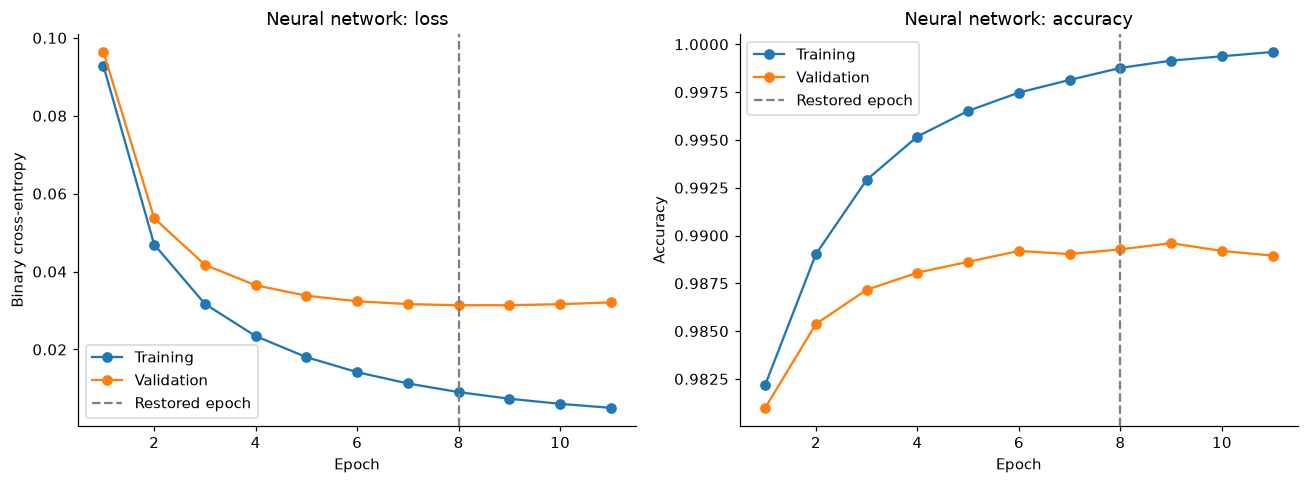

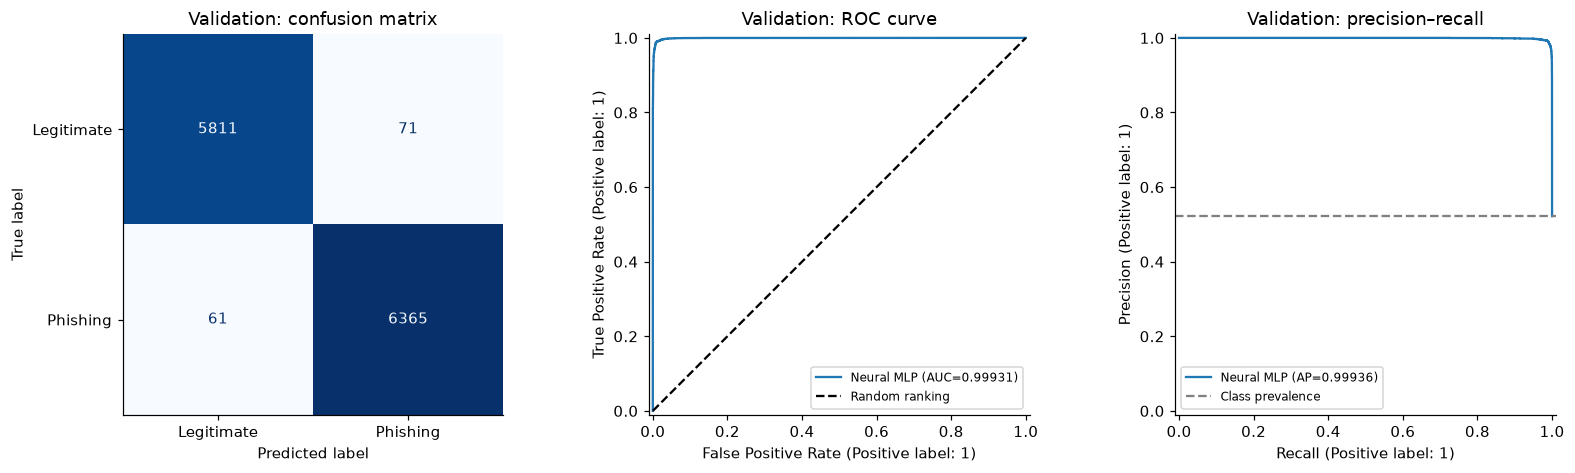

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, title in zip(axes, ['loss', 'accuracy'], ['Neural network: loss', 'Neural network: accuracy']):
    ax.plot(history.epoch, history[f'train_{metric}'], marker='o', label='Training')
    ax.plot(history.epoch, history[f'val_{metric}'], marker='o', label='Validation')
    ax.axvline(best_epoch, color='grey', linestyle='--', label='Restored epoch')
    ax.set(title=title, xlabel='Epoch', ylabel='Binary cross-entropy' if metric == 'loss' else 'Accuracy')
    ax.legend()
show_figure('training_curves')

def evaluation_plots(y, probabilities, title, filename):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
    ConfusionMatrixDisplay.from_predictions(y, probabilities >= THRESHOLD,
        display_labels=['Legitimate','Phishing'], cmap='Blues', colorbar=False, ax=axes[0])
    axes[0].set_title(f'{title}: confusion matrix')
    RocCurveDisplay.from_predictions(y, probabilities, name=selected_name, ax=axes[1])
    axes[1].lines[0].set_label(f'{selected_name} (AUC={roc_auc_score(y, probabilities):.5f})')
    axes[1].plot([0,1], [0,1], 'k--', label='Random ranking')
    axes[1].set_title(f'{title}: ROC curve')
    axes[1].legend(loc='lower right', fontsize=8)
    PrecisionRecallDisplay.from_predictions(y, probabilities, name=selected_name, ax=axes[2])
    axes[2].lines[0].set_label(f'{selected_name} (AP={average_precision_score(y, probabilities):.5f})')
    axes[2].axhline(np.mean(y), color='grey', linestyle='--', label='Class prevalence')
    axes[2].set_title(f'{title}: precision–recall')
    axes[2].legend(loc='lower left', fontsize=8)
    show_figure(filename)

evaluation_plots(y_val, selected_val_prob, 'Validation', 'selected_validation_evaluation')

## 15. Error Analysis
These are actual **validation** mistakes from the selected model. We inspect up to three false positives and three false negatives in fixed split order, with message excerpts capped at 450 characters. The comments are hypotheses tied to visible wording, not verified explanations or new ground-truth labels. No test example is used to change the model.

In [10]:
errors = validation[['source_row', 'text_combined', 'label']].copy()
errors['p_phishing'] = selected_val_prob
errors['predicted'] = (selected_val_prob >= THRESHOLD).astype(int)
error_examples = []
for kind, truth, pred in [('False positive', 0, 1), ('False negative', 1, 0)]:
    subset = errors[(errors.label == truth) & (errors.predicted == pred)].head(3)
    print(f'{kind}: showing {len(subset)} of {int(((errors.label == truth) & (errors.predicted == pred)).sum())}')
    for _, row in subset.iterrows():
        excerpt = row.text_combined[:450]
        terms = set(analyser(row.text_combined))
        financial = sorted(terms & {'account', 'bank', 'money', 'credit', 'payment', 'offer', 'free'})
        routine = sorted(terms & {'meeting', 'report', 'attached', 'please', 'thanks', 'subject'})
        if kind == 'False positive':
            reason = (f'Shared commercial/account vocabulary {financial} may resemble positive training messages.'
                      if financial else 'The excerpt may share topic/source vocabulary with positive training messages; text alone cannot establish intent.')
        else:
            reason = (f'Routine correspondence wording {routine} may mask positive-labelled content.'
                      if routine else 'The positive label may depend on context or a spam pattern that the limited TF-IDF vocabulary misses.')
        item = {'type': kind, 'source_row': int(row.source_row), 'true_label': LABELS[truth],
                'prediction': LABELS[pred], 'p_phishing': float(row.p_phishing), 'excerpt': excerpt,
                'possible_reason': reason}
        error_examples.append(item)
        display(Markdown(f'**{kind} — source row {int(row.source_row)}; P(Phishing)={row.p_phishing:.4f}**'))
        print(excerpt)
        print('Possible explanation:', reason, '\n')
(ROOT / 'reports/validation_errors.json').write_text(json.dumps(error_examples, indent=2))

False positive: showing 3 of 71


**False positive — source row 44752; P(Phishing)=0.6217**

ustreamtv ifmblfjfkustreamtv thank signing ustreamtv username password information please keep information safe username tonyandrewmeyer password nothere get started watching live shows live concerts broadcasting events video messaging friends sign account httpwwwustreamtv thanks ustreamtv tip 1 easy broadcast events anywhere world check httpustreamtvgetstarted ____________________________________________ invite friends join ustreamtv httpustream
Possible explanation: Shared commercial/account vocabulary ['account'] may resemble positive training messages. 



**False positive — source row 1634; P(Phishing)=0.5018**

income tax hey tonya said staple copy b w 2 tax return one camp says copy c payer state copy copy b recipient keep records one send one school says send b confused one doctor say tonya due date love get private free email http www hotmail com
Possible explanation: Shared commercial/account vocabulary ['free'] may resemble positive training messages. 



...

**False negative — source row 28151; P(Phishing)=0.3026**

new accts exclusive free ebooks software 300 bonus function var cookiename combinedpop var count getcookie cookiename count null count 1 setcookie cookiename count exp var url http www casinoblasters com marketing _ tools exitpop exit php member marketexpress var windowwidth 454 var windowheight 324 var windowtop screen availheight 2 windowheight 2 var windowleft screen availwidth 2 windowwidth 2 var windowprops toolbar 0 location 0 status 0 menu
Possible explanation: The positive label may depend on context or a spam pattern that the limited TF-IDF vocabulary misses. 



**False negative — source row 27186; P(Phishing)=0.0368**

funny dimness antithesis gnats miscellaneous besetting cornfield linguistics visualizer guatemala cardinally honeydew flier rocketed abort armagnac tighter cornfield staggered indirectly incompressible erratum titled preemptive doubtlessly repeater waldo secretariat fork sari navigators saves hips methane congressionally rebecca penises phone 521 557 6435 mobile 524 609 5684 email samueldalton shimaguni com
Possible explanation: The positive label may depend on context or a spam pattern that the limited TF-IDF vocabulary misses. 



4251

## 16. Explainable AI
For the linear baseline, coefficients identify globally associated terms: positive coefficients raise phishing log-odds; negative coefficients lower them. These are correlations with training labels, including possible source artefacts.

For the **selected model**, we also use local token removal: remove all occurrences of one of the 20 strongest TF-IDF unigrams in a message, re-vectorize, and measure the change in P(Phishing). A positive decrease means the removed word supported the phishing score. This works for either selected model without SHAP/LIME dependencies. It is a sensitivity probe, not a causal explanation, and contributions do not sum to the prediction because removal changes normalisation and neighbouring bigrams.

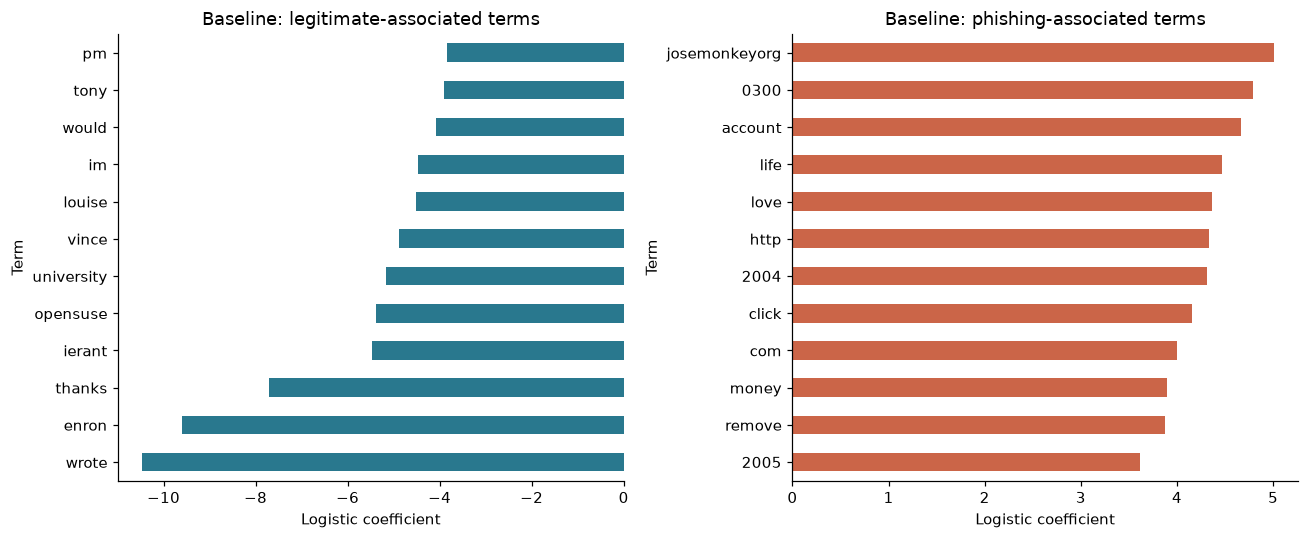

Validation example; true class: Legitimate
semitic syntax conference morphology workshop call papers conference syntax semitic languages june 2627 workshop morphology semitic languages june 23 successful first semitic syntax conference usc may 1988 department linguistics university illinois urbana champaign invites abstracts second semitic syntax conference held june 2627 1999 conference pr


,term,probability_drop
0,edu,-9.700302e-07
1,linguistics,-9.158489e-07
2,university,-8.729971e-07
3,conference,-7.479007e-07
4,languages,-6.782956e-07


Validation example; true class: Phishing
bren ishmael srms63hinetnet exhrbemilla jovovich stunning porno dvd znttwgthe dvd shocking xhrbef go site thu 07 aug 2008 003548 0000 kickup mpeg4 cameron diaz


,term,probability_drop
0,07,0.000763
1,aug,0.000363
2,thu,0.000317
3,0000,0.000227
4,shocking,0.000212


In [11]:
feature_names = vectorizer.get_feature_names_out()
weights = pd.Series(baseline.coef_[0], index=feature_names)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
weights.nsmallest(12).sort_values().plot.barh(ax=axes[0], color='#29788e')
weights.nlargest(12).sort_values().plot.barh(ax=axes[1], color='#cb6548')
axes[0].set(title='Baseline: legitimate-associated terms', xlabel='Logistic coefficient', ylabel='Term')
axes[1].set(title='Baseline: phishing-associated terms', xlabel='Logistic coefficient', ylabel='Term')
show_figure('baseline_global_explanation')

def explain_selected(text, limit=5):
    tokens = analyser(text)
    # The reconstructed token stream has the same TF-IDF features as the original text.
    x = vectorizer.transform([text]).tocsr()
    original_probability = float(selected_pipeline.predict_proba([text])[0, 1])
    candidates = sorted([(feature_names[i], float(v)) for i,v in zip(x.indices, x.data)
                         if ' ' not in feature_names[i]], key=lambda pair: (-pair[1], pair[0]))[:20]
    if not candidates:
        return []
    altered = [' '.join(token for token in tokens if token != term) for term,_ in candidates]
    changed_prob = selected_pipeline.predict_proba(altered)[:, 1]
    rows = [{'term': term, 'probability_drop': original_probability - float(p)}
            for (term,_),p in zip(candidates, changed_prob)]
    return sorted(rows, key=lambda row: (-abs(row['probability_drop']), row['term']))[:limit]

for label in [0, 1]:
    example = validation.loc[validation.label == label].iloc[0]
    print('Validation example; true class:', LABELS[label])
    print(example.text_combined[:350])
    display(pd.DataFrame(explain_selected(example.text_combined)))

## 17. FINAL TEST SET EVALUATION
Model selection, threshold, preprocessing, and early stopping are now frozen. This cell is the only aggregate test-evaluation step. The selected model predicts the untouched test set once; all test plots and statistics below reuse those probabilities. We do not compare both models on test data or retrain after seeing these results.

,accuracy,precision,recall,f1,auc_roc,loss
Neural MLP: FINAL TEST,0.990006,0.989896,0.990974,0.990435,0.999115,0.031831


              precision    recall  f1-score   support

  Legitimate     0.9901    0.9889    0.9895      5882
    Phishing     0.9899    0.9910    0.9904      6426

    accuracy                         0.9900     12308
   macro avg     0.9900    0.9900    0.9900     12308
weighted avg     0.9900    0.9900    0.9900     12308

Average precision: 0.99916


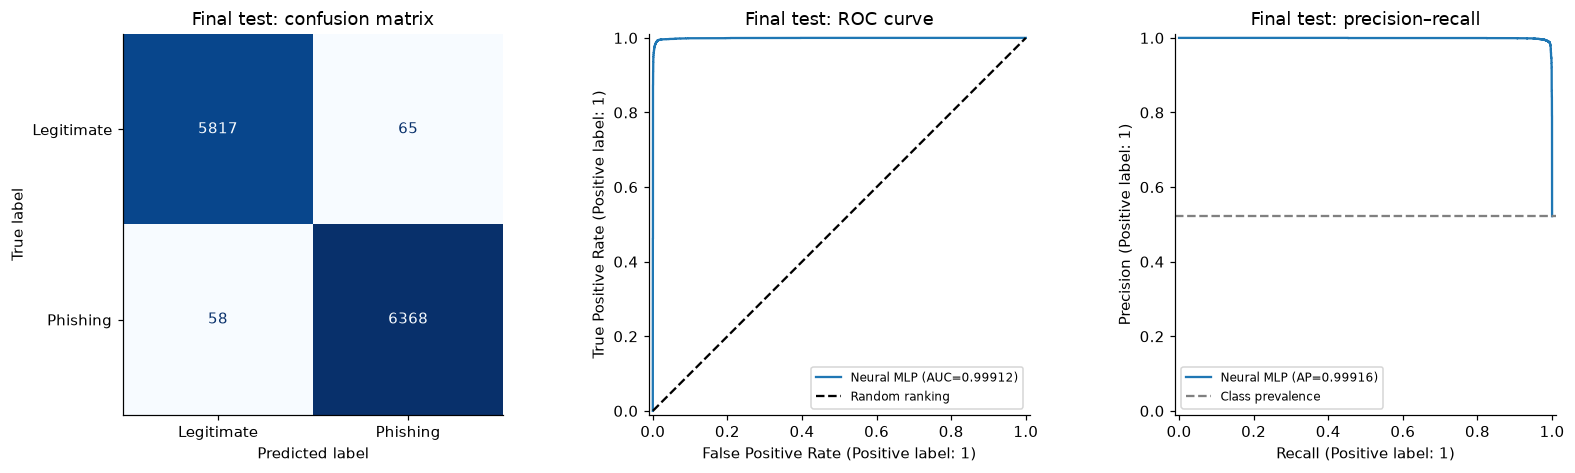

Of **6,426** phishing-labelled test messages, **58** were missed (**0.90%** false-negative rate). **65** legitimate-labelled messages triggered false alarms. A missed phishing message may allow credential theft or fraud. These results describe this corpus and random split; they do not establish reliability on current real email.

In [12]:
X_test = vectorizer.transform(test.text_combined)
y_test = test.label.to_numpy()
test_prob = selected_model.predict_proba(X_test)[:, 1]
test_predictions = (test_prob >= THRESHOLD).astype(int)
test_metrics = metric_scores(y_test, test_prob)
test_ap = float(average_precision_score(y_test, test_prob))
test_cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
display(pd.DataFrame([test_metrics], index=[f'{selected_name}: FINAL TEST']))
print(classification_report(y_test, test_predictions, target_names=['Legitimate','Phishing'], digits=4))
print('Average precision:', round(test_ap, 5))
evaluation_plots(y_test, test_prob, 'Final test', 'final_test_evaluation')
tn, fp, fn, tp = map(int, test_cm.ravel())
display(Markdown(f'Of **{fn + tp:,}** phishing-labelled test messages, **{fn:,}** were missed '
    f'(**{100 * fn/(fn+tp):.2f}%** false-negative rate). **{fp:,}** legitimate-labelled messages triggered false alarms. '
    'A missed phishing message may allow credential theft or fraud. These results describe this corpus and random split; '
    'they do not establish reliability on current real email.'))

## 18. Example Predictions
Dataset examples below are from validation, not extra test probes. Manually written examples are labelled as demonstrations and are not included in reported metrics. Confidence is the predicted class probability, not a calibrated guarantee. An input with no known vocabulary is explicitly identified in the application.

In [13]:
manual_texts = [
    'Your account has been suspended. Verify your password immediately at https://account-check.example/login.',
    'Hi team, please find the meeting agenda attached. We will review the project report tomorrow. Thanks.',
    'Congratulations! You have won a cash prize. Send your banking details to claim the money now.',
    'Hi Sam, are we still meeting for lunch on Friday? Please let me know.']
example_rows = []
for source, text, true_class in [('Manual demonstration', t, 'Not labelled') for t in manual_texts] + [
    ('Validation dataset', validation.loc[validation.label == label].iloc[0].text_combined,
     LABELS[label]) for label in [0,1]]:
    p = float(selected_pipeline.predict_proba([text])[0,1])
    prediction = int(p >= THRESHOLD)
    example_rows.append({'source': source, 'text_excerpt': text[:350], 'true_class': true_class,
                         'prediction': LABELS[prediction], 'confidence': max(p, 1-p), 'p_phishing': p})
display(pd.DataFrame(example_rows))
print('Local indicators for the first manual demonstration:')
display(pd.DataFrame(explain_selected(manual_texts[0])))

,source,text_excerpt,true_class,prediction,confidence,p_phishing
0,Manual demonstration,Your account has been suspended. Verify your password immediately at https://account-check.example/login.,Not labelled,Phishing,0.995447,0.995447
1,Manual demonstration,"Hi team, please find the meeting agenda attached. We will review the project report tomorrow. Thanks.",Not labelled,Legitimate,0.999882,0.000118
2,Manual demonstration,Congratulations! You have won a cash prize. Send your banking details to claim the money now.,Not labelled,Phishing,0.993795,0.993795
3,Manual demonstration,"Hi Sam, are we still meeting for lunch on Friday? Please let me know.",Not labelled,Legitimate,0.998848,0.001152
4,Validation dataset,semitic syntax conference morphology workshop call papers conference syntax semitic languages june 2627 workshop morphology semitic languages june 23 succes...,Legitimate,Legitimate,0.999999,0.000001
5,Validation dataset,bren ishmael srms63hinetnet exhrbemilla jovovich stunning porno dvd znttwgthe dvd shocking xhrbef go site thu 07 aug 2008 003548 0000 kickup mpeg4 cameron diaz,Phishing,Phishing,0.999543,0.999543


Local indicators for the first manual demonstration:


,term,probability_drop
0,immediately,0.003881
1,verify,0.003827
2,suspended,0.003678
3,account,0.003387
4,example,-0.002071


## 19. Model Saving
We save both experiment models and the fitted vectorizer for inspection, plus a single selected-model Pipeline used by the API. The Pipeline contains exactly the preprocessing and classifier evaluated above. A JSON manifest records the mapping, threshold, dataset hash, version, and selection rule. Only load trusted locally generated joblib files.

The assertions below compare reloaded and in-memory predictions, and verify that the raw CSV hash is unchanged.

In [14]:
joblib.dump(vectorizer, ROOT / 'models/tfidf_vectorizer.joblib', compress=3)
joblib.dump(baseline, ROOT / 'models/logistic_regression.joblib', compress=3)
joblib.dump(neural, ROOT / 'models/neural_mlp.joblib', compress=3)
joblib.dump(selected_pipeline, ROOT / 'models/phishing_pipeline.joblib', compress=3)
(ROOT / 'models/label_mapping.json').write_text(json.dumps(LABELS, indent=2))
metadata = {'selected_model': selected_name, 'threshold': THRESHOLD,
            'label_mapping': {str(k):v for k,v in LABELS.items()}, 'dataset_sha256': raw_sha256,
            'sklearn_version': sklearn.__version__, 'seed': SEED,
            'selection_rule': 'Highest validation F1, then recall, then ROC AUC; exact tie favours baseline',
            'input': 'Plain subject/body text; preprocessing is inside the saved Pipeline',
            'limitation': 'Positive labels include spam; probability is not calibrated proof of phishing.'}
(ROOT / 'models/model_metadata.json').write_text(json.dumps(metadata, indent=2))
reloaded = joblib.load(ROOT / 'models/phishing_pipeline.joblib')
np.testing.assert_allclose(reloaded.predict_proba(manual_texts), selected_pipeline.predict_proba(manual_texts), rtol=1e-7)
parity_texts = manual_texts + ['ACCOUNT   Verify\nPassword!', 'Café meeting report', 'zzzzunknownqqqq', '!!!']
parity = [{'text': t, 'p_phishing': float(selected_pipeline.predict_proba([t])[0,1])} for t in parity_texts]
(ROOT / 'reports/inference_reference.json').write_text(json.dumps(parity, indent=2))
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == raw_sha256
summary = {'dataset': {'filename': 'phishing_email.csv', 'raw_rows': len(df), 'clean_rows': len(clean),
                       'columns': list(df.columns), 'raw_class_counts': {str(k):int(v) for k,v in class_counts.items()},
                       'missing_values': {k:int(v) for k,v in df.isna().sum().items()},
                       'blank_text_rows': int(df.text_combined.fillna('').str.strip().eq('').sum()),
                       'duplicate_rows': int(df.duplicated().sum()), 'sha256': raw_sha256},
           'cleaning': audit, 'splits': split_table.to_dict(orient='records'),
           'validation': comparison.to_dict(orient='index'), 'selected_model': selected_name,
           'test': test_metrics, 'test_average_precision': test_ap, 'test_confusion_matrix': test_cm.tolist(),
           'training': {'requested_epochs': MAX_EPOCHS, 'trained_epochs': len(history),
                        'best_epoch': best_epoch, 'best_validation_loss': best_loss, 'patience': PATIENCE,
                        'early_stopping_triggered': wait >= PATIENCE, 'seconds': training_seconds}}
(ROOT / 'reports/results.json').write_text(json.dumps(summary, indent=2))
print('Saved models, metadata, logs, and inference parity examples. Reload parity and raw integrity checks passed.')

Saved models, metadata, logs, and inference parity examples. Reload parity and raw integrity checks passed.


## 20. Results Discussion
The following discussion is generated directly from this run. Accuracy is meaningful alongside class balance; precision and recall expose the different costs of alerts and missed attacks. ROC AUC describes ranking, whereas the confusion matrix describes the fixed 0.5 decision threshold. PR performance should be interpreted relative to the roughly balanced test prevalence, which may be unlike a real inbox.

In [15]:
best_row = history.loc[history.epoch == best_epoch].iloc[0]
display(Markdown(
    f'The selected **{selected_name}** achieved test accuracy **{test_metrics["accuracy"]:.4f}**, '
    f'precision **{test_metrics["precision"]:.4f}**, recall **{test_metrics["recall"]:.4f}**, '
    f'F1 **{test_metrics["f1"]:.4f}**, ROC AUC **{test_metrics["auc_roc"]:.4f}**, '
    f'and log loss **{test_metrics["loss"]:.4f}**. Average precision was **{test_ap:.4f}**. '
    f'The confusion matrix contains TN={tn}, FP={fp}, FN={fn}, TP={tp}.\n\n'
    f'The neural model trained for **{len(history)}** of {MAX_EPOCHS} requested epochs and restored epoch '
    f'**{best_epoch}**. At that checkpoint, training loss was **{best_row.train_loss:.5f}** '
    f'and validation loss was **{best_row.val_loss:.5f}**; the gap was '
    f'**{best_row.val_loss-best_row.train_loss:.5f}**. '
    'The loss curves show whether continued training improves generalisation or only training fit. '
    'Restoring the best validation checkpoint reduces the impact of later overfitting.\n\n'
    'The experiment supports a classroom screening prototype on this dataset. It does not justify automatic '
    'deletion or a guarantee that legitimate predictions are safe. Spam/phishing label conflation, already-processed '
    'text, source-specific terms, residual campaign similarity, absent time/source metadata, and uncalibrated probabilities '
    'limit deployment conclusions. Further evaluation should use independently labelled recent emails, campaign-disjoint '
    'and time-based splits, calibration data, and monitoring of false negatives and false positives. '
    'None of those future checks has been claimed as completed here.'))

The selected **Neural MLP** achieved test accuracy **0.9900**, precision **0.9899**, recall **0.9910**, F1 **0.9904**, ROC AUC **0.9991**, and log loss **0.0318**. Average precision was **0.9992**. The confusion matrix contains TN=5817, FP=65, FN=58, TP=6368.

The neural model trained for **11** of 30 requested epochs and restored epoch **8**. At that checkpoint, training loss was **0.00905** and validation loss was **0.03135**; the gap was **0.02230**. The loss curves show whether continued training improves generalisation or only training fit. Restoring the best validation checkpoint reduces the impact of later overfitting.

The experiment supports a classroom screening prototype on this dataset. It does not justify automatic deletion or a guarantee that legitimate predictions are safe. Spam/phishing label conflation, already-processed text, source-specific terms, residual campaign similarity, absent time/source metadata, and uncalibrated probabilities limit deployment conclusions. Further evaluation should use independently labelled recent emails, campaign-disjoint and time-based splits, calibration data, and monitoring of false negatives and false positives. None of those future checks has been claimed as completed here.

## 21. Conclusion
We inspected the real supplied dataset, documented cleaning, created disjoint train/validation/test sets, fitted TF-IDF only on training text, compared a linear baseline with a neural model, logged metrics per epoch, restored the best neural checkpoint, selected using validation metrics, and evaluated the selected model once on the test set within this run. Figures are displayed inline and saved in `figures/`.

The saved Pipeline provides consistent application preprocessing. See `README.md` for installation, operation, testing, and project limitations.

**Reproducibility:** a fresh Run All repeats this fixed experiment. Do not repeatedly change settings in response to test performance; a genuinely new model-development cycle would require a new untouched evaluation dataset.